✅ 成功加载数据，样本量 N=25

步骤 1: 变量构建与信度优化

🔍 [信度分析] 购买意愿 (Purchase)
   - 原始 Alpha (3 items): 0.401
   - 💡 优化建议: 删除 'Q20_Purchase_Interest'
   - 🚀 优化后 Alpha: 0.659

🔍 [信度分析] 感知侵入性 (Intrusiveness)
   - 原始 Alpha (5 items): 0.576
   - 💡 优化建议: 删除 'Q26_Invasive'
   - 🚀 优化后 Alpha: 0.593

🔍 [信度分析] 信任感 (Trust)
   - 原始 Alpha (9 items): 0.813
   - ✅ 保留所有题项 (无需删除)

步骤 2: 假设检验 (T-Test & Cohen's d)

>>> 分组分析: 性别准确度
   --- 广告怀疑论 (Skepticism) ---
   - 误读组 Mean: 2.75
   - 准确组 Mean: 3.81
   - 差异检验: t = -6.264, p = 0.00000
   - 效应量 (Cohen's d): -2.610
   --- 感知侵入性 (Intrusiveness) ---
   - 误读组 Mean: 3.03
   - 准确组 Mean: 2.02
   - 差异检验: t = 5.282, p = 0.00002
   - 效应量 (Cohen's d): 2.201
   --- 购买意愿 (Purchase) ---
   - 误读组 Mean: 3.33
   - 准确组 Mean: 4.19
   - 差异检验: t = -2.846, p = 0.00916
   - 效应量 (Cohen's d): -1.186

>>> 分组分析: 年龄准确度
   --- 广告怀疑论 (Skepticism) ---
   - 误读组 Mean: 3.10
   - 准确组 Mean: 3.74
   - 差异检验: t = -2.724, p = 0.01209
   - 效应量 (Cohen's d): -1.091
   --- 感知侵入性 (Intrusiveness) ---
   - 误读组 Mean: 2.6

/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],


📊 已保存图表: gender_effects_plot.png


/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],
/var/folders/11/lck8sq7s4gnd7ql3gsv9lhnm0000gn/T/ipykernel_9004/2243415773.py:150: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=group_col, y=var, data=df, ax=axes[i],


📊 已保存图表: age_effects_plot.png
📊 已保存图表: correlation_matrix_plot.png

✅ 分析完成！


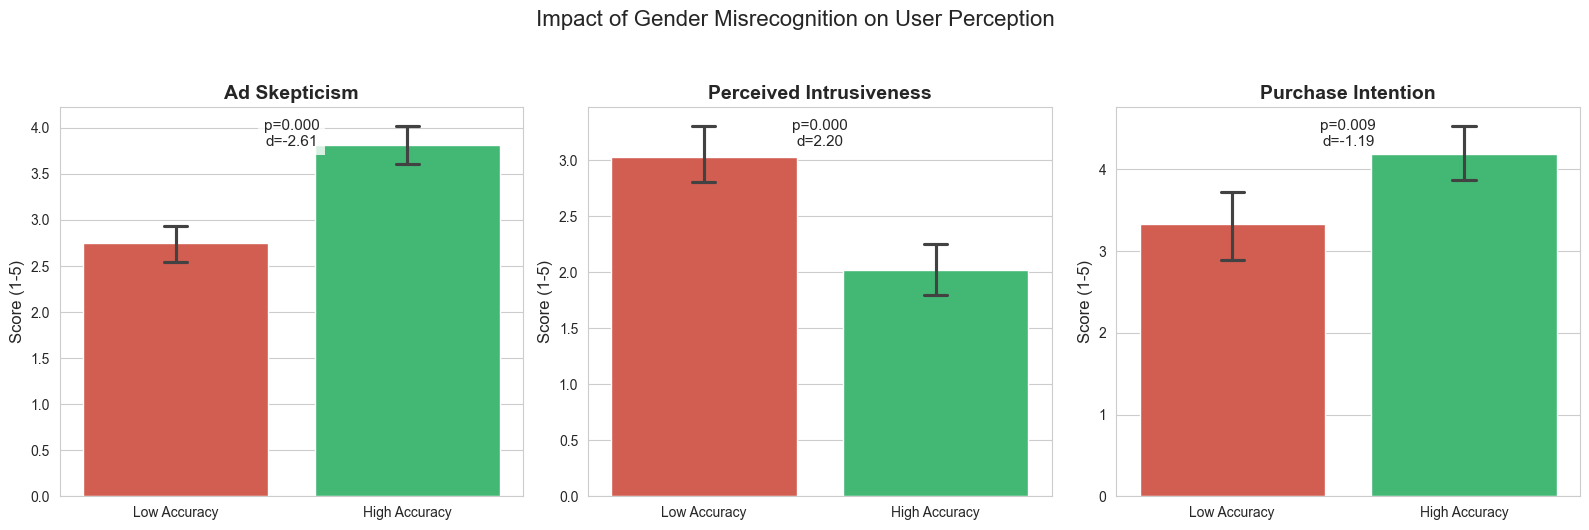

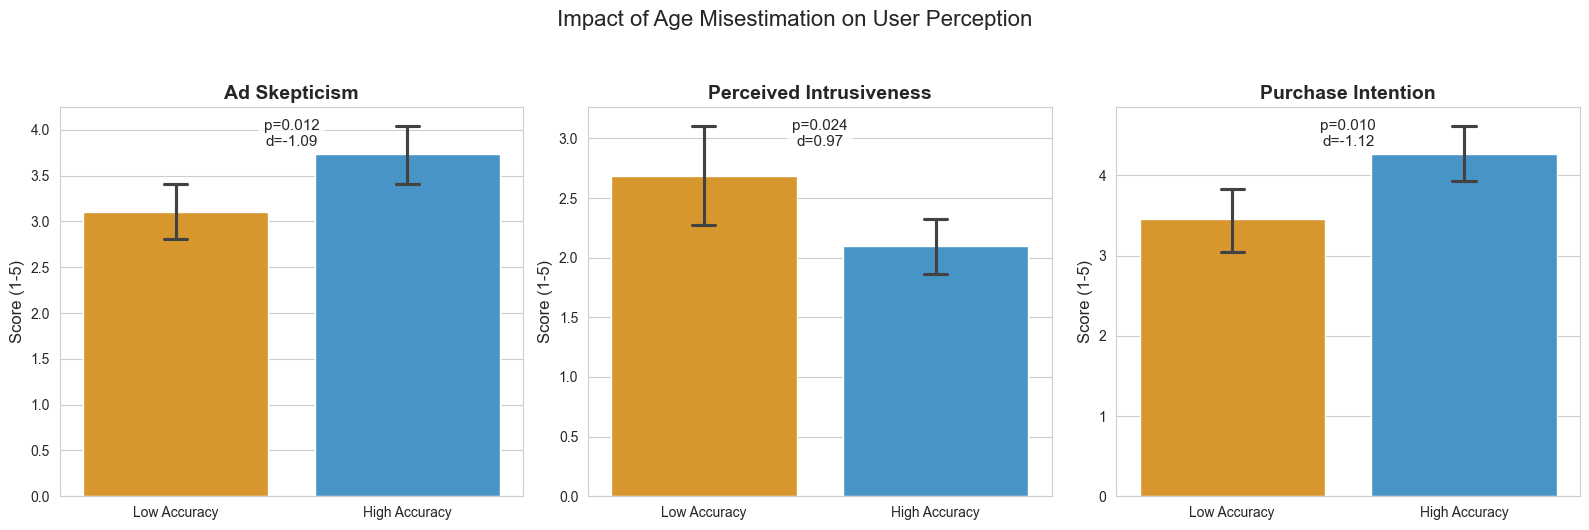

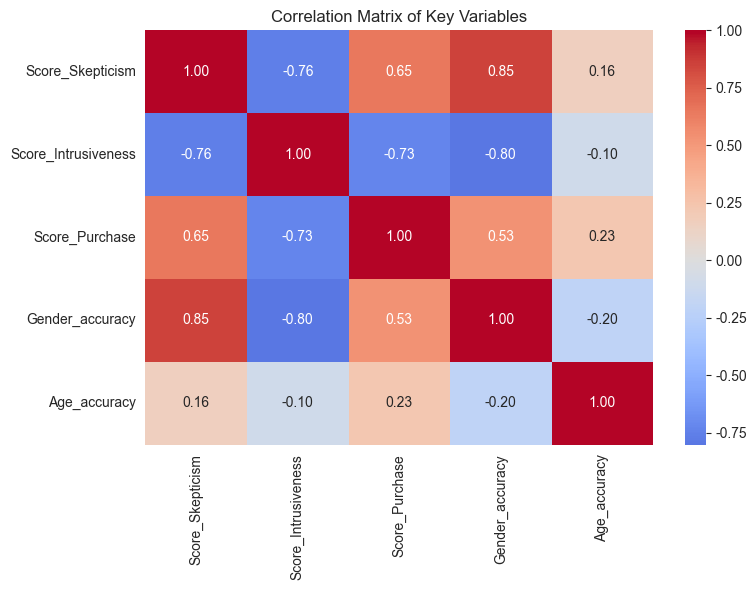

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. 配置与数据加载
# ==========================================
FILE_PATH = 'optimized_data_final.csv'

def load_data(file_path):
    try:
        df = pd.read_csv(file_path)
        print(f"✅ 成功加载数据，样本量 N={len(df)}")
        return df
    except FileNotFoundError:
        print("❌ 错误：未找到文件，请确保 csv 文件在当前目录下。")
        return None

# ==========================================
# 2. 统计辅助函数
# ==========================================
def calculate_cronbach_alpha(df_items):
    """计算标准化 Cronbach's Alpha"""
    item_scores = df_items.dropna()
    if item_scores.shape[1] < 2: return 0.0
    item_vars = item_scores.var(axis=0, ddof=1)
    total_score_var = item_scores.sum(axis=1).var(ddof=1)
    n_items = df_items.shape[1]
    if total_score_var == 0: return 0.0
    return (n_items / (n_items - 1)) * (1 - (item_vars.sum() / total_score_var))

def calculate_cohens_d(group1, group2):
    """计算 Cohen's d 效应量"""
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    d = (np.mean(group1) - np.mean(group2)) / pooled_std
    return d

def optimize_scale(df, name, items):
    """自动优化量表信度"""
    print(f"\n🔍 [信度分析] {name}")
    initial_alpha = calculate_cronbach_alpha(df[items])
    print(f"   - 原始 Alpha ({len(items)} items): {initial_alpha:.3f}")
    
    best_alpha = initial_alpha
    item_to_drop = None
    
    for item in items:
        sub_items = [i for i in items if i != item]
        if len(sub_items) < 2: continue
        alpha = calculate_cronbach_alpha(df[sub_items])
        if alpha > best_alpha:
            best_alpha = alpha
            item_to_drop = item
            
    final_items = items
    if item_to_drop:
        print(f"   - 💡 优化建议: 删除 '{item_to_drop}'")
        print(f"   - 🚀 优化后 Alpha: {best_alpha:.3f}")
        final_items = [i for i in items if i != item_to_drop]
    else:
        print(f"   - ✅ 保留所有题项 (无需删除)")
        
    return final_items

# ==========================================
# 3. 主分析逻辑
# ==========================================
def main():
    df = load_data(FILE_PATH)
    if df is None: return

    # --- A. 变量构建与清洗 ---
    print("\n" + "="*50)
    print("步骤 1: 变量构建与信度优化")
    print("="*50)
    
    # 定义原始题项
    cols_purchase = ['Q20_Purchase_Interest', 'Q21_Purchase_Thoughts', 'Q22_Purchase_Probability']
    cols_intrusive = ['Q23_Intrusive', 'Q24_Disturbing', 'Q25_Irritating', 'Q26_Invasive', 'Q27_Uncomfortable']
    cols_trust = df.columns[6:15].tolist() # Q1-Q9
    
    # 运行优化
    final_purchase = optimize_scale(df, "购买意愿 (Purchase)", cols_purchase)
    final_intrusive = optimize_scale(df, "感知侵入性 (Intrusiveness)", cols_intrusive)
    final_trust = optimize_scale(df, "信任感 (Trust)", cols_trust)
    
    # 计算得分
    df['Score_Purchase'] = df[final_purchase].mean(axis=1)
    df['Score_Intrusiveness'] = df[final_intrusive].mean(axis=1)
    df['Score_Trust'] = df[final_trust].mean(axis=1)
    df['Score_Skepticism'] = 6 - df['Score_Trust']

    # --- B. 假设检验 (Gender & Age) ---
    print("\n" + "="*50)
    print("步骤 2: 假设检验 (T-Test & Cohen's d)")
    print("="*50)
    
    target_vars = {
        'Score_Skepticism': '广告怀疑论 (Skepticism)',
        'Score_Intrusiveness': '感知侵入性 (Intrusiveness)',
        'Score_Purchase': '购买意愿 (Purchase)'
    }
    
    # 定义分组
    df['Group_Gender'] = df['Gender_accuracy'].apply(lambda x: 'High Accuracy' if x >= 4 else 'Low Accuracy')
    df['Group_Age'] = df['Age_accuracy'].apply(lambda x: 'High Accuracy' if x >= 4 else 'Low Accuracy')

    def run_analysis(group_col, group_name):
        print(f"\n>>> 分组分析: {group_name}")
        stats_list = []
        for col, name in target_vars.items():
            group_high = df[df[group_col] == 'High Accuracy'][col]
            group_low = df[df[group_col] == 'Low Accuracy'][col]
            
            t_stat, p_val = stats.ttest_ind(group_low, group_high, equal_var=True)
            d = calculate_cohens_d(group_low, group_high)
            
            stats_list.append({'Variable': name, 'P-Value': p_val, 'Cohens_d': d})

            print(f"   --- {name} ---")
            print(f"   - 误读组 Mean: {group_low.mean():.2f}")
            print(f"   - 准确组 Mean: {group_high.mean():.2f}")
            print(f"   - 差异检验: t = {t_stat:.3f}, p = {p_val:.5f}")
            print(f"   - 效应量 (Cohen's d): {d:.3f}")
        return stats_list

    gender_stats = run_analysis('Group_Gender', '性别准确度')
    age_stats = run_analysis('Group_Age', '年龄准确度')

    # --- C. 可视化绘图 ---
    print("\n" + "="*50)
    print("步骤 3: 生成图表")
    print("="*50)
    
    sns.set_style("whitegrid")
    plt.rcParams['font.sans-serif'] = ['Arial'] 
    plt.rcParams['axes.unicode_minus'] = False

    # 通用绘图函数
    def plot_effects(group_col, stats_data, title, filename, palette):
        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        plot_vars = ['Score_Skepticism', 'Score_Intrusiveness', 'Score_Purchase']
        plot_titles = ['Ad Skepticism', 'Perceived Intrusiveness', 'Purchase Intention']
        
        for i, var in enumerate(plot_vars):
            sns.barplot(x=group_col, y=var, data=df, ax=axes[i], 
                        palette=palette,
                        order=['Low Accuracy', 'High Accuracy'], capsize=.1, errorbar=('ci', 95))
            
            # 标注统计数据
            res = next(item for item in stats_data if item["Variable"] == target_vars[var])
            p_txt = f"p={res['P-Value']:.3f}\nd={res['Cohens_d']:.2f}"
            
            axes[i].set_title(plot_titles[i], fontsize=14, fontweight='bold')
            axes[i].set_ylabel("Score (1-5)", fontsize=12)
            axes[i].set_xlabel("")
            axes[i].text(0.5, 0.9, p_txt, ha='center', transform=axes[i].transAxes, fontsize=11, 
                         bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

        plt.suptitle(title, fontsize=16, y=1.05)
        plt.tight_layout()
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"📊 已保存图表: {filename}")

    # 1. Gender Effects (原有)
    plot_effects('Group_Gender', gender_stats, 
                 'Impact of Gender Misrecognition on User Perception', 
                 'gender_effects_plot.png', 
                 {'Low Accuracy': '#e74c3c', 'High Accuracy': '#2ecc71'})
    
    # 2. Age Effects (新增!)
    plot_effects('Group_Age', age_stats, 
                 'Impact of Age Misestimation on User Perception', 
                 'age_effects_plot.png', 
                 {'Low Accuracy': '#f39c12', 'High Accuracy': '#3498db'})

    # 3. Correlation Matrix
    plt.figure(figsize=(8, 6))
    corr_cols = ['Score_Skepticism', 'Score_Intrusiveness', 'Score_Purchase', 'Gender_accuracy', 'Age_accuracy']
    corr_matrix = df[corr_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt=".2f")
    plt.title('Correlation Matrix of Key Variables')
    plt.tight_layout()
    plt.savefig('correlation_matrix_plot.png', dpi=300)
    print("📊 已保存图表: correlation_matrix_plot.png")
    
    print("\n✅ 分析完成！")

if __name__ == "__main__":
    main()